[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vvvvvivekkk/AI-Engineer/blob/main/13-fine-tuning/notebooks/01-lora-from-scratch.ipynb)

# 01 - LoRA from scratch in PyTorch

**Goal:** understand LoRA (Low-Rank Adaptation) by building it yourself in about 20 lines, then compare it with the real `peft` library.

**Words you need**
- **Matrix** - a grid of numbers. A neural-network layer is mostly a weight matrix W.
- **Rank** - roughly, how many independent "directions" of information a matrix holds.
- **Low-rank update** - a change to W written as B x A, where B and A are thin matrices.
- **Frozen** - weights that are not changed by training.

Runs on any CPU in under a minute. No downloads, no keys.

## Step 1 - Imports

In [1]:
import math
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
torch.manual_seed(0)
print("torch", torch.__version__)

torch 2.15.0+cpu


## Step 2 - What "low rank" means, with a picture

We build a 64 x 64 matrix that is secretly made of only 3 "ingredients" (3 outer products) plus a little noise. **SVD** (singular value decomposition) is a tool that measures how much each independent direction contributes; the contributions are called **singular values**. A low-rank matrix has only a few large ones.

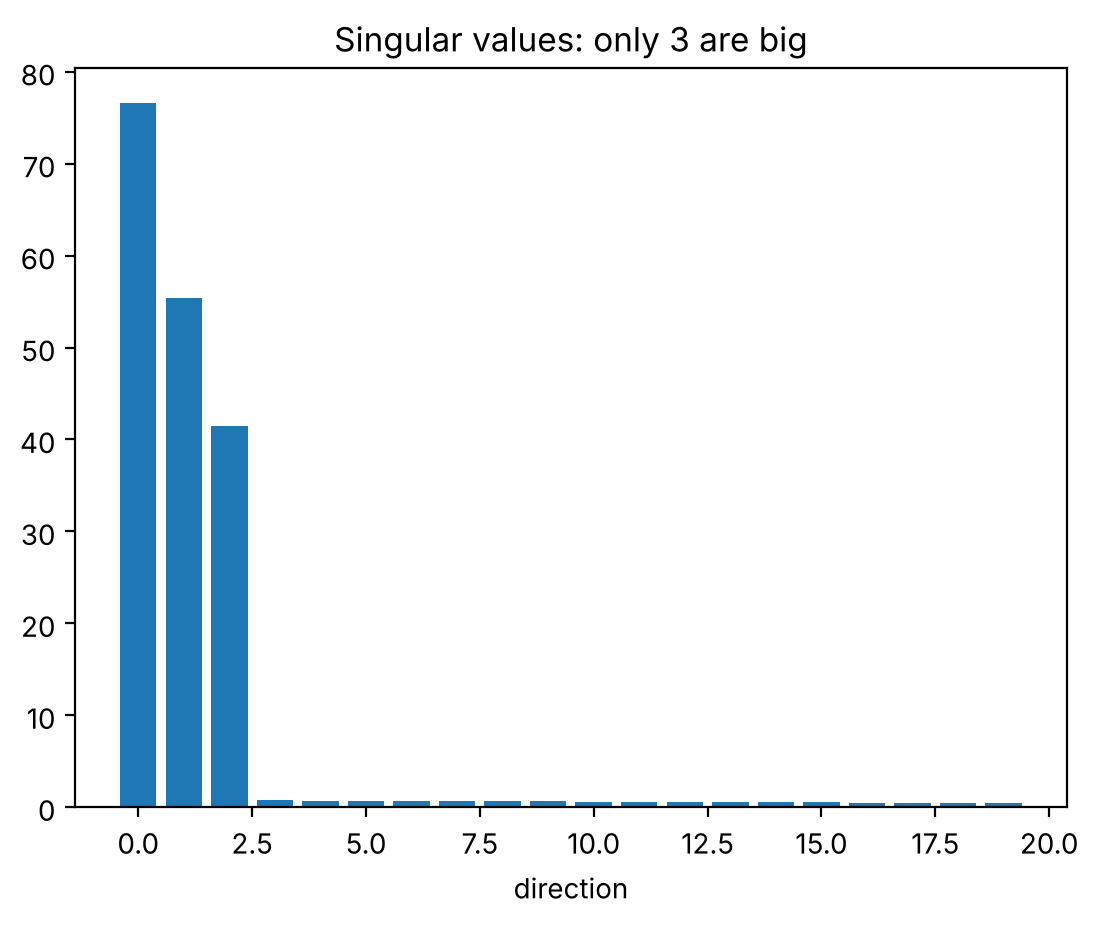

first 5 singular values: [76.6, 55.4, 41.5, 0.8, 0.7]


In [2]:
d = 64
M = sum(torch.randn(d, 1) @ torch.randn(1, d) for _ in range(3))   # 3 ingredients
M = M + 0.05 * torch.randn(d, d)                                      # a little noise
S = torch.linalg.svdvals(M)
plt.bar(range(20), S[:20]); plt.title("Singular values: only 3 are big"); plt.xlabel("direction"); plt.show()
print("first 5 singular values:", [round(s, 1) for s in S[:5].tolist()])

## Step 3 - Rebuild the matrix from thin pieces

If only 3 directions matter, we can write M ≈ B x A with B of shape 64 x 3 and A of shape 3 x 64. That is 384 numbers instead of 4,096 - and the error is tiny. LoRA bets that the *change* needed for fine-tuning is also low rank.

In [3]:
U, S_full, Vh = torch.linalg.svd(M)
for r in [1, 2, 3, 8]:
    B = U[:, :r] * S_full[:r]          # 64 x r
    A = Vh[:r, :]                      # r x 64
    err = (M - B @ A).norm() / M.norm()
    print(f"rank {r}: B {tuple(B.shape)} x A {tuple(A.shape)} -> {B.numel() + A.numel():5d} numbers, relative error {err:.3f}")

rank 1: B (64, 1) x A (1, 64) ->   128 numbers, relative error 0.671
rank 2: B (64, 2) x A (2, 64) ->   256 numbers, relative error 0.403
rank 3: B (64, 3) x A (3, 64) ->   384 numbers, relative error 0.029
rank 8: B (64, 8) x A (8, 64) ->  1024 numbers, relative error 0.025


## Step 4 - Count LoRA's savings on a real-size layer

A typical attention matrix in a 7B-parameter model is 4096 x 4096. With rank r = 8, LoRA trains r x (d + k) numbers instead of d x k.

In [4]:
def lora_params(d, k, r):
    return r * (d + k)

d = k = 4096
for r in [4, 8, 16, 64]:
    full, lora = d * k, lora_params(d, k, r)
    print(f"r={r:3d}: full {full:,}  LoRA {lora:,}  ({100 * lora / full:.2f}% of the layer)")

r=  4: full 16,777,216  LoRA 32,768  (0.20% of the layer)
r=  8: full 16,777,216  LoRA 65,536  (0.39% of the layer)
r= 16: full 16,777,216  LoRA 131,072  (0.78% of the layer)
r= 64: full 16,777,216  LoRA 524,288  (3.12% of the layer)


## Step 5 - A LoRA linear layer, written by hand

`LoRALinear` wraps an existing `nn.Linear`:
1. It **freezes** the original layer (`requires_grad = False`).
2. It creates **A** (r x k, small random numbers) and **B** (d x r, all zeros).
3. Output = original output + (alpha / r) x B A x.

Because B starts at zero, the wrapped layer gives *exactly* the same output as the original before training. (`peft` uses the same initialisation idea.)

In [5]:
class LoRALinear(nn.Module):
    def __init__(self, base: nn.Linear, r: int = 4, alpha: float = 8, dropout: float = 0.0):
        super().__init__()
        self.base = base
        for p in self.base.parameters():
            p.requires_grad = False                      # freeze W and bias
        d, k = base.out_features, base.in_features
        self.A = nn.Parameter(torch.empty(r, k))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))  # small random start
        self.B = nn.Parameter(torch.zeros(d, r))          # zeros -> no change at start
        self.scaling = alpha / r
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.base(x) + (self.dropout(x) @ self.A.T @ self.B.T) * self.scaling

    def merged_weight(self):
        return self.base.weight + self.scaling * (self.B @ self.A)

base = nn.Linear(64, 64)
lora = LoRALinear(base, r=2, alpha=4)
x = torch.randn(5, 64)
print("same output before training:", torch.allclose(base(x), lora(x)))
trainable = sum(p.numel() for p in lora.parameters() if p.requires_grad)
total = sum(p.numel() for p in lora.parameters())
print(f"trainable {trainable} of {total} parameters ({100 * trainable / total:.1f}%)")

same output before training: True
trainable 256 of 4416 parameters (5.8%)


## Step 6 - Train it on a toy "new task"

We pretend `base` is a pre-trained layer. The new task needs the layer to behave like W + dW, where dW is a hidden **rank-2** change. We train only A and B with the **mean squared error** loss (average squared difference between prediction and target) and see whether LoRA can discover dW. We try ranks 1, 2 and 8.

r=1: final loss 3.54e-01, error in recovered dW 0.617


r=2: final loss 1.26e-08, error in recovered dW 0.000


r=8: final loss 1.97e-11, error in recovered dW 0.000


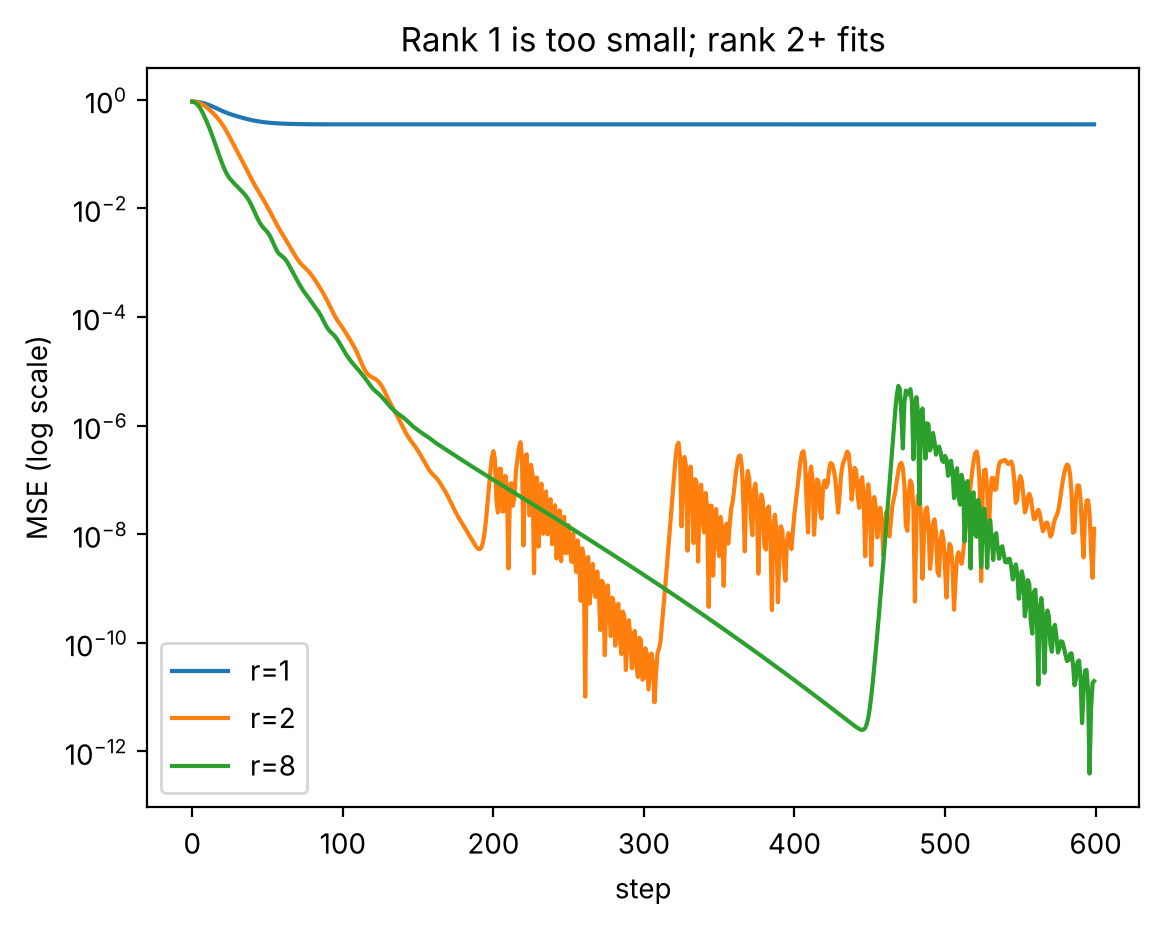

base weights unchanged: True


In [6]:
dW_true = 0.1 * torch.randn(64, 2) @ torch.randn(2, 64)          # hidden rank-2 change
X = torch.randn(2000, 64)
Y = (X @ (base.weight + dW_true).T + base.bias).detach()            # targets for the new task

results = {}
for r in [1, 2, 8]:
    torch.manual_seed(0)
    layer = LoRALinear(base, r=r, alpha=2 * r)
    opt = torch.optim.Adam([layer.A, layer.B], lr=1e-2)
    losses = []
    for step in range(600):
        loss = ((layer(X) - Y) ** 2).mean()
        opt.zero_grad(); loss.backward(); opt.step()
        losses.append(loss.item())
    learned = layer.scaling * (layer.B @ layer.A)
    rel = ((learned - dW_true).norm() / dW_true.norm()).item()
    results[r] = layer
    plt.plot(losses, label=f"r={r}")
    print(f"r={r}: final loss {losses[-1]:.2e}, error in recovered dW {rel:.3f}")
plt.yscale("log"); plt.xlabel("step"); plt.ylabel("MSE (log scale)"); plt.legend(); plt.title("Rank 1 is too small; rank 2+ fits"); plt.show()
print("base weights unchanged:", base.weight.requires_grad is False)

## Step 7 - Merge the adapter into the weights

**Merging** computes W' = W + (alpha/r) B A once. A plain `nn.Linear` with W' gives the same outputs as base + adapter, with no extra cost at inference time.

In [7]:
layer = results[2]
merged = nn.Linear(64, 64)
with torch.no_grad():
    merged.weight.copy_(layer.merged_weight())
    merged.bias.copy_(base.bias)
x = torch.randn(3, 64)
print("merged == base + adapter:", torch.allclose(merged(x), layer(x), atol=1e-5))

merged == base + adapter: True


## Step 8 - The same idea with the `peft` library

`peft` does all of this for any model. We give it a tiny two-layer network and say which layers to adapt with `target_modules`. Look at the printed structure: each targeted `Linear` now has a `base_layer` plus `lora_A` and `lora_B` - exactly our design.

In [8]:
from peft import LoraConfig, get_peft_model

class TinyMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(16, 32)
        self.fc2 = nn.Linear(32, 4)
    def forward(self, x):
        return self.fc2(torch.relu(self.fc1(x)))

peft_model = get_peft_model(TinyMLP(), LoraConfig(r=4, lora_alpha=8, target_modules=["fc1", "fc2"]))
peft_model.print_trainable_parameters()
print(peft_model.base_model.model.fc1)

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


trainable params: 336 || all params: 1,012 || trainable%: 33.2016
lora.Linear(
  (base_layer): Linear(in_features=16, out_features=32, bias=True)
  (lora_dropout): ModuleDict(
    (default): Identity()
  )
  (lora_A): ModuleDict(
    (default): Linear(in_features=16, out_features=4, bias=False)
  )
  (lora_B): ModuleDict(
    (default): Linear(in_features=4, out_features=32, bias=False)
  )
  (lora_embedding_A): ParameterDict()
  (lora_embedding_B): ParameterDict()
  (lora_magnitude_vector): ModuleDict()
)


## Step 9 - peft merging

`merge_and_unload()` folds the adapters into the weights and returns the plain model - the same as our Step 7.

In [9]:
with torch.no_grad():                                   # give B some non-zero values so merging matters
    for name, p in peft_model.named_parameters():
        if "lora_B" in name:
            p.add_(0.1 * torch.randn_like(p))
x = torch.randn(2, 16)
before = peft_model(x)
plain = peft_model.merge_and_unload()
print(type(plain).__name__, "| outputs match:", torch.allclose(before, plain(x), atol=1e-5))

TinyMLP | outputs match: True


## What you learned

- A low-rank matrix can be stored as two thin matrices B (d x r) and A (r x k).
- LoRA: output = W x + (alpha/r) B A x, with W frozen and B starting at zero.
- r = 8 on a 4096 x 4096 layer trains only 0.39% of it.
- If r is too small for the change you need, LoRA underfits (r = 1 above).
- Merging folds the adapter into W; `peft` implements the same design.
- Next: `02-quantisation-explained.ipynb`, the other half of QLoRA.